In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil

import discriminator as Discriminator
import generator as Generator
import feature_extractor as feature_extractor

import utils.functions as fc
import utils.util_deep_learning as udl
import utils.util as util
import utils.visualization as vis


tf.keras.backend.set_image_data_format("channels_first")
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')


2024-05-06 01:43:04.313878: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-06 01:43:04.964598: E tensorflow/stream_executor/cuda/cuda_blas.cc:2981] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-05-06 01:43:09.397927: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /cluster/home/agustinc/miniconda3/envs/s4_old/lib:
2024-05-06 01:43:09.398198: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: lib

SERVER: True


/cluster/home/agustinc/miniconda3/envs/s4_old/lib/python3.9/site-packages/tensorflow_addons/utils/tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(
/cluster/home/agustinc/miniconda3/envs/s4_old/lib/python3.9/site-packages/tensorflow_addons/utils/ensure_tf_install.py:53: UserWarning: Tensorflow Addons supports using Python ops for all Tensorflow versions above or equal to 2.13.0 and strictly below 2.16.0 (nightly versions are not supported). 
 The versions of TensorFlow you are currently using is 2.10.1 and is not supported. 
Some things might work, some things might not.
If you were to enco

INFO:tensorflow:Mixed precision compatibility check (mixed_float16): OK
Your GPU will likely run quickly with dtype policy mixed_float16 as it has compute capability of at least 7.0. Your GPU: NVIDIA A100-PCIE-40GB, compute capability 8.0


## Visualize data

In [2]:
# %matplotlib widget

# data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
#                                 batch_size=1, 
#                                 image_size=(192, 224, 192), 
#                                 channels_first=True,
#                                 shuffle=True, 
#                                 nb_patients=10, 
#                                 shuffle_before_selecting=False, 
#                                 server=False,
#                                 start_from=0)

# batch_h3, batch_h4 = data_train[0]
# print(data_train.get_iter_ids())
# fc.imgshow_3D("", batch_h4[0,0])


### Validation visualization

In [3]:
def show_generated_image(id, G, img_size, current_plane=116, show=True):
    def fast_resieze(img, img_size):
        return img[:img_size[0], :img_size[1], :img_size[2]]
    
    img_hunt3 = fast_resieze(pil.load_preprocessed_image(3, id, absolute=True)[0], img_size)
    img_hunt4 = fast_resieze(pil.load_preprocessed_image(4, id, absolute=True)[0], img_size)

    img_gen_h4 = G(np.expand_dims(np.expand_dims(img_hunt3, axis=0), axis=0), training=False)
    img_gen_h4 = img_gen_h4[0,0].numpy()
    img_gen_h4[img_gen_h4 < 0] = 0
    img_gen_h4 = img_gen_h4 / np.max(img_gen_h4)

    return vis.shows_3_images(img_hunt3, img_hunt4, img_gen_h4, current_plane=current_plane, show=show)



### Loss functions

In [4]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=False)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = (real_loss + fake_loss)/2
    return total_loss

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def feature_extractor_loss(Fe, h4_real, h4_fake):
    feat_h4_real_list = Fe(h4_real, training=False)
    feat_h4_fake_list = Fe(h4_fake, training=False)

    loss = tf.constant(0.0, dtype=tf.float16)
    for i in range(len(feat_h4_real_list)):
        loss += tf.reduce_mean(tf.abs(feat_h4_real_list[i] - feat_h4_fake_list[i]))
    loss /= len(feat_h4_real_list)
    return tf.cast(loss, tf.float32)

In [5]:
@tf.function
def train_step(G, D, Fe, h3_batch, h4_batch, g_optimizer, d_optimizer):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        h4_fake = G(h3_batch, training=True)

        real_output = D(h4_batch, training=True)
        fake_output = D(h4_fake, training=True)

        _gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)

        l1_loss = tf.reduce_mean(tf.abs(h4_batch[h4_batch>0] - h4_fake[h4_batch>0]))
        percetual_loss = feature_extractor_loss(Fe, h4_batch, h4_fake)
        # percetual_loss = 0.0
        gen_loss = _gen_loss + 25.0 * l1_loss + 25.0 * percetual_loss


    gradients_of_generator = gen_tape.gradient(gen_loss, G.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, D.trainable_variables)

    g_optimizer.apply_gradients(zip(gradients_of_generator, G.trainable_variables))
    d_optimizer.apply_gradients(zip(gradients_of_discriminator, D.trainable_variables))

    return gen_loss, disc_loss, l1_loss, percetual_loss



In [6]:
# data_train = DataLoader(f"{pil.get_base_folder()}data/data_reduced/train", batch_size=1, image_size=(200, 240, 240), shuffle=True, channels_first=False)
# data = data_train[0]

# # dloader = DataLoader(root_folder=f"data_test", batch_size=3, image_size=(200, 240, 240))
# fc.imgshow_3D(f"Original", data[0][0,...,0], current_plane=150)

### Training

2024-05-06 01:43:18.801168: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-05-06 01:43:20.317647: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1616] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 38206 MB memory:  -> device: 0, name: NVIDIA A100-PCIE-40GB, pci bus id: 0000:82:00.0, compute capability: 8.0



Epoch 1/1000


2024-05-06 01:43:25.334039: I tensorflow/stream_executor/cuda/cuda_dnn.cc:384] Loaded cuDNN version 8100
2024-05-06 01:43:26.393739: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


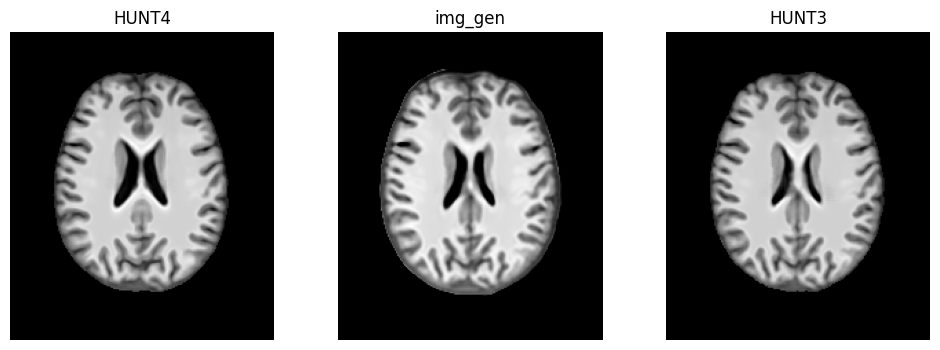

Initializing...:   0%|          | 0/620 [00:00<?, ?it/s]/cluster/home/agustinc/miniconda3/envs/s4_old/lib/python3.9/site-packages/tensorflow/python/framework/tensor_util.py:437: RuntimeWarning: overflow encountered in cast
  nparray = values.astype(dtype.as_numpy_dtype)
gen_loss: 21.03110	disc_loss: 0.11209	l1_loss: 0.35425	percetual_loss: 0.13916: 100%|██████████| 620/620 [17:27<00:00,  1.69s/it]


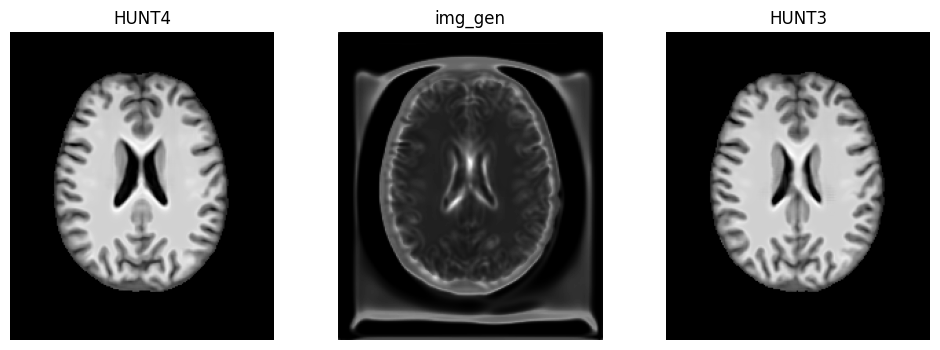


Epoch 2/1000


gen_loss: 27.45006	disc_loss: 0.00110	l1_loss: 0.42216	percetual_loss: 0.16025:   1%|▏         | 9/620 [00:14<18:23,  1.81s/it]

In [7]:

def train(num_epochs, batch_size, monitor_each, show=False):
    # input_shape = (193,229,193)
    input_shape = (192,224,192)
    # input_shape = (64,64,64)
    current_plane = 116

    # ---- Models
    D = Discriminator.create_discriminator_model(input_shape)
    G = Generator.create_generator_model(input_shape)
    Fe = feature_extractor.create_features_extractor((1,)+input_shape, pil.get_genesis_weights_path_name())

    # Freeze features extractor layers
    # udl.freeze_layers(Fe, -1)

    # optimizers
    inital_lr = 1e-7
    g_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_optimizer = tf.keras.optimizers.Adam(inital_lr)

    g_optimizer_monitor = udl.LearningRateMonitor(g_optimizer, inital_lr, 0.5, 1e-10, 10, "loss")
    d_optimizer_monitor = udl.LearningRateMonitor(d_optimizer, inital_lr, 0.5, 1e-10, 10, "loss")

    # ---- Data
    server = False
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=True,
                                    shuffle=True, 
                                    nb_patients=620, 
                                    shuffle_before_selecting=False, 
                                    exclude_ids=["08202"],
                                    server=server)
    # visualization
    nb_loss = 4
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)

    log_dir = f"{current_path}/models/logs/train" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
    summary_writer = tf.summary.create_file_writer(log_dir)

    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(g_optimizer=g_optimizer,
                                     d_optimizer=d_optimizer,
                                    G=G,
                                    D=D)
    # restore checkpoint
    # checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))
    checkpoint.restore(f"{checkpoint_dir}/ckpt-{31}")
    for epoch in range(0,num_epochs):
        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        if epoch == 0 and show:
            show_generated_image("08202", G, input_shape, current_plane=current_plane, show=show)
        
        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (h3_batch, h4_batch) in enumerate(data_train):
  
            gen_loss, disc_loss, l1_loss, percetual_loss = train_step(G, D, Fe, h3_batch, h4_batch, g_optimizer, d_optimizer)
            acum_loss_train.update((gen_loss, disc_loss, l1_loss, percetual_loss))
            losses_text = acum_loss_train.get_progress_bar_text(['gen_loss', 'disc_loss', 'l1_loss', 'percetual_loss'])

            progress_bar.set_description(desc=losses_text)
            progress_bar.update(1)
        del progress_bar

        
        # # ---- Learning rate
        # if epoch > 44 and epoch % 22 == 0:
        #     inital_lr *= 0.5
        #     g_optimizer.learning_rate = inital_lr
        #     d_optimizer.learning_rate = inital_lr

        loss_mean = acum_loss_train.get_mean()

        g_optimizer_monitor.on_epoch_end(loss_mean[0])
        d_optimizer_monitor.on_epoch_end(loss_mean[1])

        if (epoch + 1) % monitor_each == 0:
            val_results = show_generated_image("08202", G, input_shape, current_plane=current_plane, show=show)

            # ---- Check points
            checkpoint.save(file_prefix=checkpoint_prefix)

            # ---- tensorboard
            with summary_writer.as_default():
                tf.summary.scalar('gen_loss', loss_mean[0], step=epoch)
                tf.summary.scalar('disc_loss', loss_mean[1], step=epoch)
                tf.summary.scalar('l1_loss', loss_mean[2], step=epoch)
                tf.summary.scalar('percetual_loss', loss_mean[3], step=epoch)

                # images
                gen_image_h4 = np.expand_dims(np.expand_dims(val_results[2], axis=-1), axis=0)
                hunt4_vs_gen_h4 = np.expand_dims(np.stack([val_results[2], val_results[1], np.zeros_like(val_results[1])], axis=-1), axis=0)
                tf.summary.image("generated H4", gen_image_h4, step=epoch)
                tf.summary.image("R: Gen H4 - G: HUNT4", hunt4_vs_gen_h4, step=epoch)
        

train(num_epochs=1000, batch_size=1, monitor_each=1, show=True)
# lat check point 12

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]